# StreamView Analytics — EP2 · Análisis exploratorio y calidad de datos
ADY1104 Visualización de Datos. Este notebook valida las reglas de integración que luego aplica Power Query y genera los gráficos estáticos del informe.

**Fuentes:** `data/raw/netflix_movies_detailed_up_to_2025.csv` y `data/raw/netflix_tv_shows_detailed_up_to_2025.csv` (sin modificar).

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath('../src'))
import pandas as pd
import eda_streamview as e
pd.set_option('display.width', 160)

## 1. Carga y diagnóstico de calidad

In [2]:
m = pd.read_csv('../data/raw/netflix_movies_detailed_up_to_2025.csv')
t = pd.read_csv('../data/raw/netflix_tv_shows_detailed_up_to_2025.csv')
print(m.shape, t.shape)
pd.DataFrame({'nulos_peliculas': m.isna().sum(), 'nulos_series': t.isna().sum()})

(16000, 18) (16000, 16)


,nulos_peliculas,nulos_series
budget,0,NaN
cast,204,1157.0
country,466,1797.0
date_added,0,0.0
description,132,3206.0
director,132,10965.0
duration,16000,0.0
genres,107,974.0
language,0,0.0
popularity,0,0.0


In [3]:
print('rating == vote_average:', (pd.concat([m,t]).rating == pd.concat([m,t]).vote_average).mean())
print('duration películas nulas:', m.duration.isna().sum(), '| valores duration series:', t.duration.unique())
print('show_id duplicados en series:', t.show_id.duplicated().sum())
print('show_id compartidos entre datasets:', len(set(m.show_id) & set(t.show_id)))
print('Títulos por año (películas):', m.release_year.value_counts().unique(), '| (series):', t.release_year.value_counts().unique())
print('Sin votos -> películas:', (m.vote_count==0).sum(), ' series:', (t.vote_count==0).sum())
print('budget=0:', (m.budget==0).sum(), ' revenue=0:', (m.revenue==0).sum(), ' budget 1-9.999:', ((m.budget>0)&(m.budget<10000)).sum())

rating == vote_average: 1.0
duration películas nulas: 16000 | valores duration series: <StringArray>
['1 Seasons']
Length: 1, dtype: str
show_id duplicados en series: 9
show_id compartidos entre datasets: 397
Títulos por año (películas): [1000] | (series): [1000]
Sin votos -> películas: 894  series: 3674
budget=0: 11153  revenue=0: 10355  budget 1-9.999: 85


**Decisiones** (documentadas en el README e informe):
1. Clave `id_contenido` = prefijo M-/T- + show_id (hay 397 IDs repetidos entre datasets).
2. Se eliminan 9 duplicados de ID en series.
3. `rating` no es clasificación etaria: es idéntica a `vote_average` → se reemplaza por *segmento de valoración*.
4. `duration` no aporta (100 % nula en películas, constante en series) → excluida.
5. Valoración sólo si `vote_count > 0`; rankings con valoración ponderada (m = 200).
6. Financiero: sólo películas con budget y revenue ≥ USD 10.000.
7. Géneros homologados entre la taxonomía de películas y la de series.

## 2. Integración (mismas reglas que Power Query)

In [4]:
a, calidad = e.cargar()
print(len(a), 'contenidos integrados')
a[['id_contenido','tipo','title','genero_principal','pais_principal','idioma','popularity','valoracion','valoracion_ponderada','es_estrella','financiero_valido','roi']].head()

31991 contenidos integrados


,id_contenido,tipo,title,genero_principal,pais_principal,idioma,popularity,valoracion,valoracion_ponderada,es_estrella,financiero_valido,roi
0,M-10192,Película,Shrek Forever After,Comedia,United States of America,Inglés,203.893,6.380,6.378140,False,True,4.561217
1,M-27205,Película,Inception,Acción y Aventura,United Kingdom,Inglés,156.242,8.369,8.357959,True,True,5.243941
2,M-12444,Película,Harry Potter and the Deathly Hallows: Part 1,Acción y Aventura,United Kingdom,Inglés,121.191,7.744,7.729301,True,True,3.817223
3,M-38757,Película,Tangled,Animación,United States of America,Inglés,111.762,7.600,7.578187,True,True,2.278699
4,M-10191,Película,How to Train Your Dragon,Ciencia Ficción y Fantasía,United States of America,Inglés,110.044,7.800,7.777842,True,True,2.999270


## 3. KPIs de validación y gráficos estáticos

In [5]:
k = e.main()

{
 "catalogo": {
  "total": 31991,
  "peliculas": 16000,
  "series": 15991,
  "paises": 147,
  "idiomas": 83,
  "generos": 22,
  "periodo": "2010–2025"
 },
 "popularidad": {
  "media_total": 42.63,
  "mediana_total": 22.07,
  "mediana_pelicula": 10.91,
  "mediana_serie": 36.2,
  "media_pelicula": 20.38,
  "media_serie": 64.88
 },
 "valoracion": {
  "promedio_total": 6.63,
  "promedio_pelicula": 6.31,
  "promedio_serie": 7.02,
  "pct_alta_o_excelente": 42.0,
  "estrellas": 3832,
  "pct_estrellas": 12.0,
  "estrellas_pelicula": 2034,
  "estrellas_serie": 1798,
  "spearman_pop_val": 0.322,
  "segmentos": {
   "Media (5–6,9)": 13687,
   "Alta (7–7,9)": 7678,
   "Sin votos": 4560,
   "Excelente (≥8)": 3844,
   "Baja (<5)": 2222
  }
 },
 "financiero": {
  "peliculas_validas": 3492,
  "pct_de_peliculas": 21.8,
  "presupuesto_total": 125628417074,
  "ingresos_totales": 367355105933,
  "presupuesto_promedio": 35976064,
  "ingreso_promedio": 105199057,
  "roi_agregado": 2.92,
  "roi_mediano": 1.

Budget revenue.png
Generos tipo.png
Ingles año.png
Modelo datos.png
Oportunidad generos.png
Paises.png
Popularidad año.png
Roi tramo.png
Wireframe resumen.png


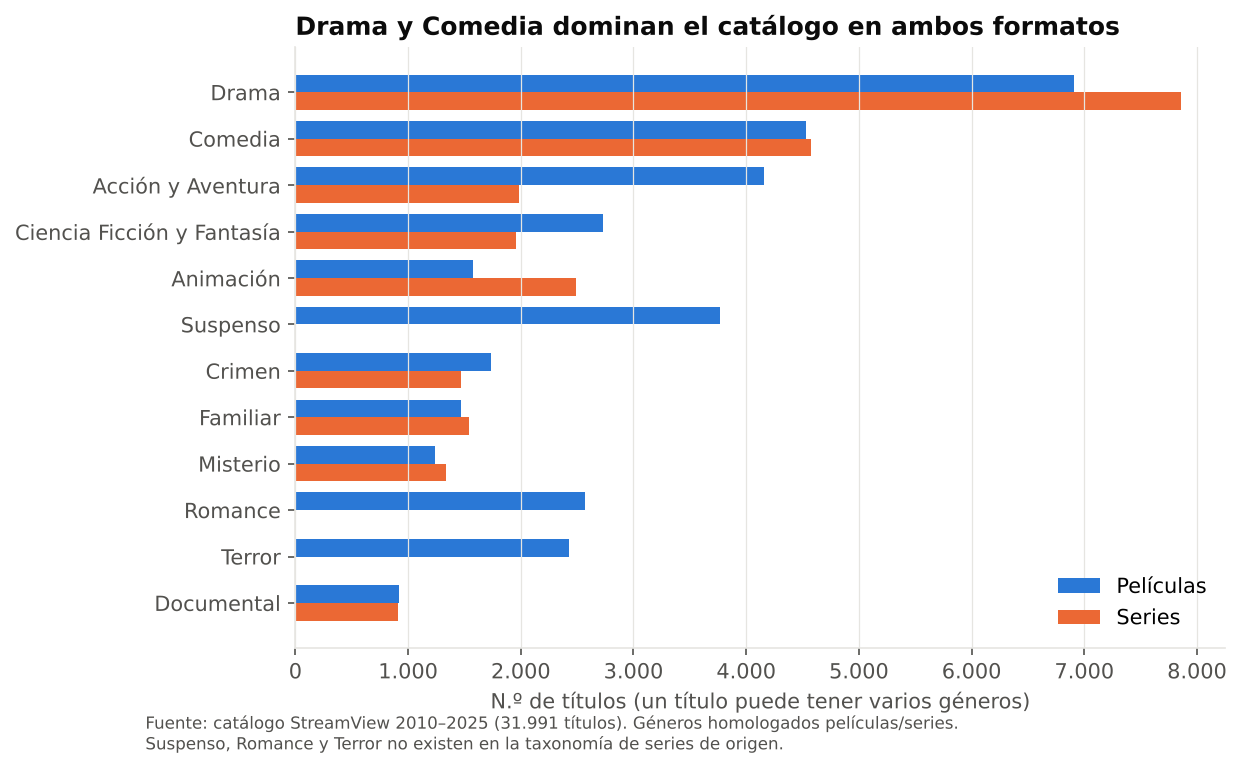

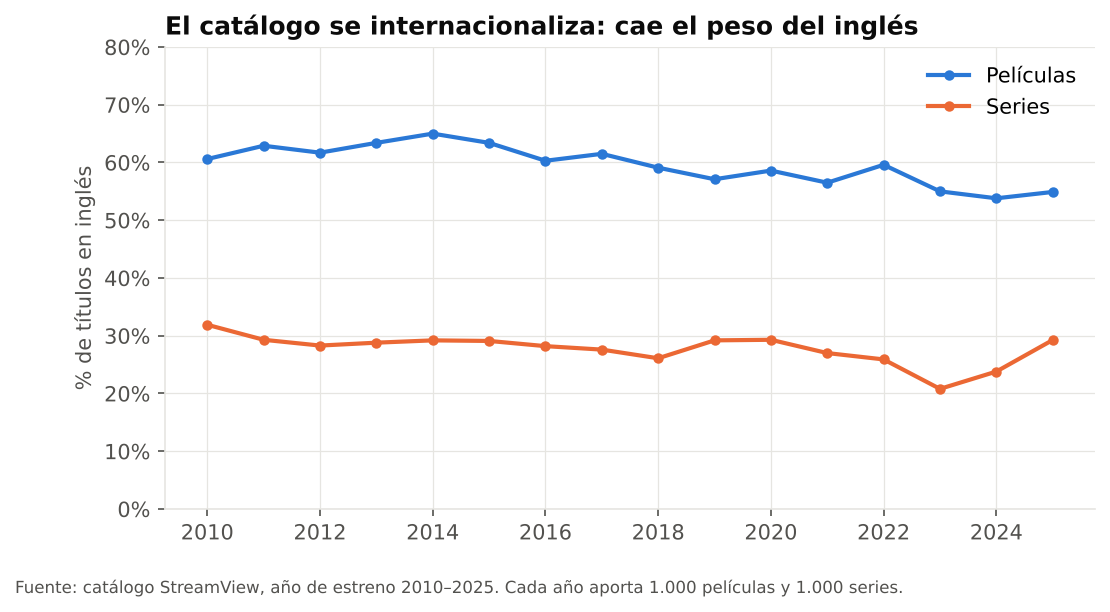

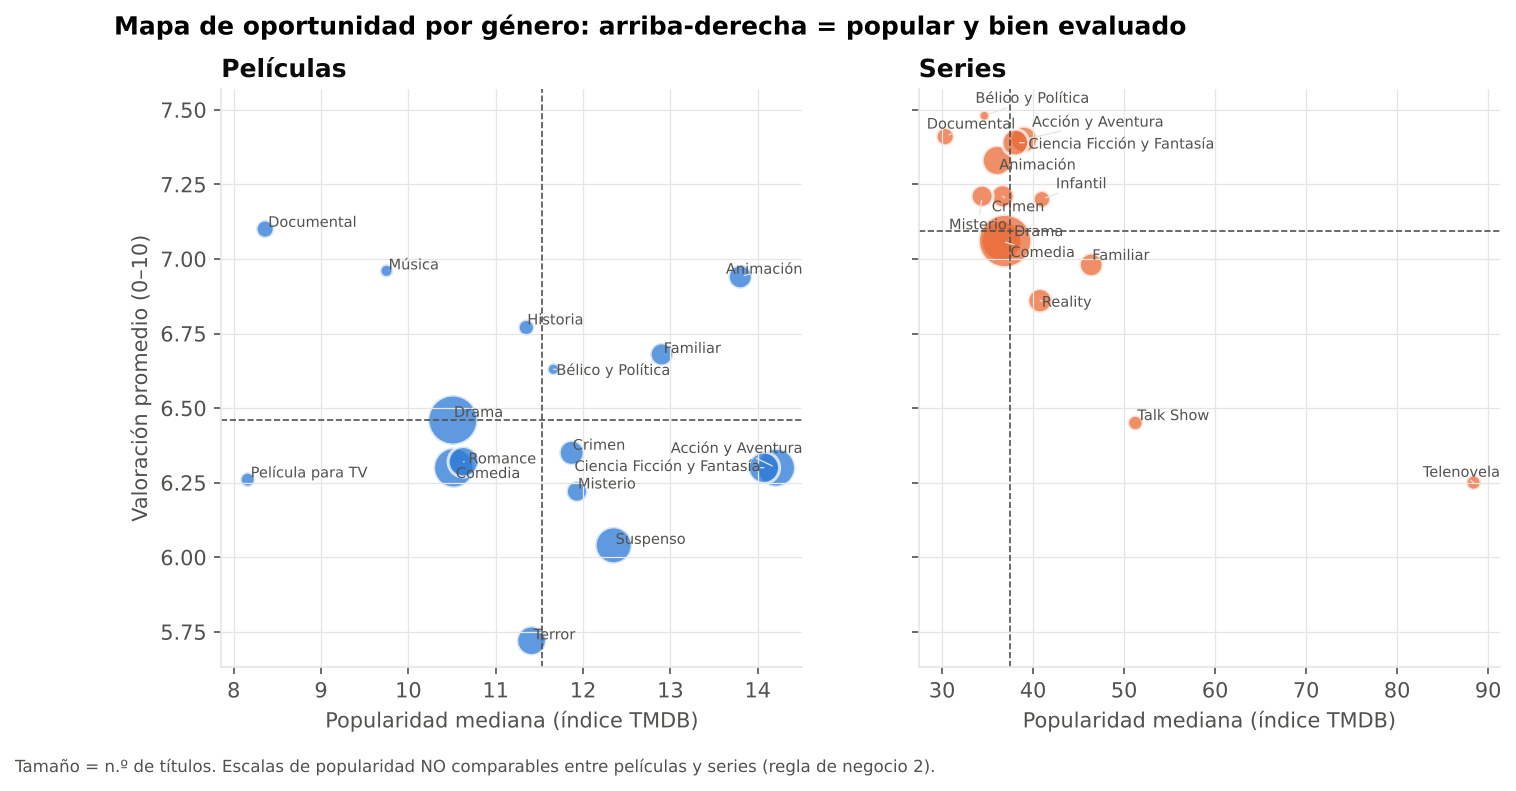

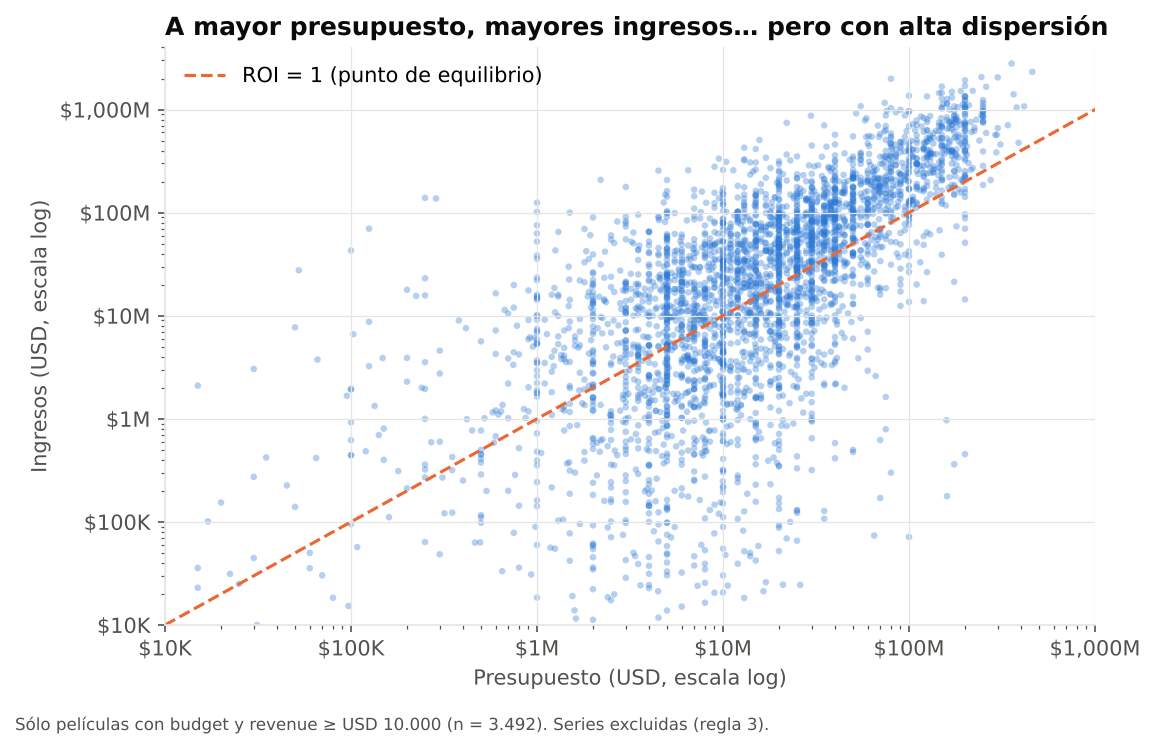

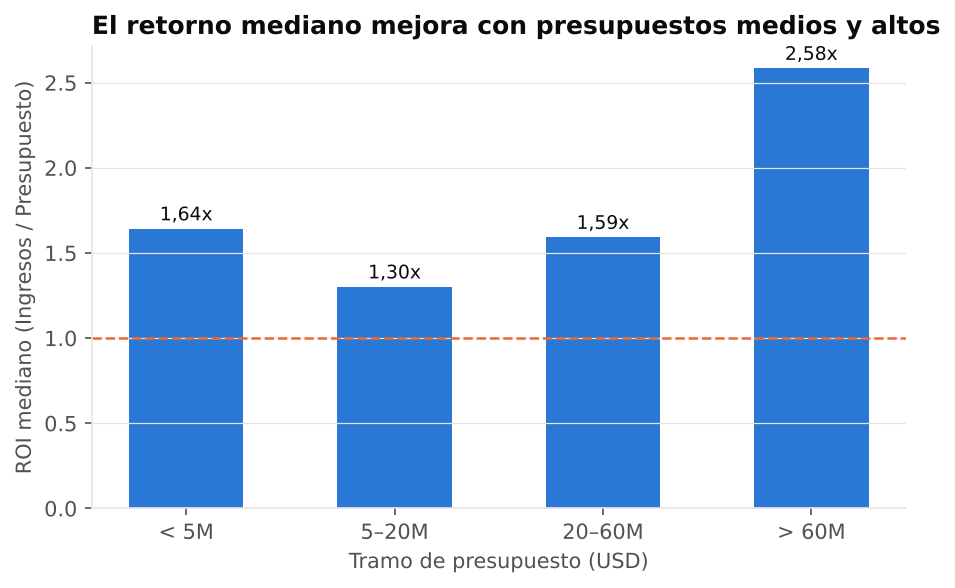

In [6]:
for f in sorted(os.listdir('../images')):
    if f.endswith('.png'): print(f)
from IPython.display import Image, display
for f in ['Generos tipo.png','Ingles año.png','Oportunidad generos.png','Budget revenue.png','Roi tramo.png']:
    display(Image(filename='../images/'+f, width=700))

## 4. Rankings clave

In [7]:
pd.DataFrame(k['top_val_pelis'])

,title,tipo,release_year,popularity,valoracion,valoracion_ponderada,vote_count
0,Interstellar,Película,2014,288.19,8.50,8.49,36625
1,Parasite,Película,2019,130.55,8.50,8.48,18728
2,Your Name.,Película,2016,93.94,8.50,8.46,11613
3,Whiplash,Película,2014,97.31,8.40,8.37,15418
4,Spider-Man: Into the Spider-Verse,Película,2018,127.26,8.40,8.37,15936
5,Inception,Película,2010,156.24,8.37,8.36,37119
6,A Silent Voice: The Movie,Película,2016,49.27,8.40,8.30,4036
7,Spider-Man: Across the Spider-Verse,Película,2023,159.51,8.35,8.29,7346
8,The Intouchables,Película,2011,72.09,8.27,8.25,17454
9,Gabriel's Inferno,Película,2020,13.41,8.41,8.25,2417


In [8]:
pd.DataFrame(k['top_val_series'])

,title,tipo,release_year,popularity,valoracion,valoracion_ponderada,vote_count
0,Arcane,Serie,2021,191.82,8.80,8.73,4932
1,Rick and Morty,Serie,2013,984.07,8.70,8.67,9992
2,Attack on Titan,Serie,2013,138.66,8.70,8.65,6603
3,Demon Slayer: Kimetsu no Yaiba,Serie,2019,87.33,8.70,8.65,6585
4,Better Call Saul,Serie,2015,286.52,8.70,8.64,5475
5,Chernobyl,Serie,2019,98.36,8.68,8.64,6636
6,Anne with an E,Serie,2017,108.61,8.70,8.63,4713
7,Stranger Things,Serie,2016,341.46,8.60,8.58,18075
8,INVINCIBLE,Serie,2021,824.06,8.63,8.56,4660
9,Hazbin Hotel,Serie,2024,108.12,8.80,8.55,1229


In [9]:
pd.DataFrame(k['top_roi'])

,title,release_year,budget_usd,revenue_usd,roi
0,Dragon Ball Super: Broly,2018,1000000.0,125002821.0,125.00
1,The Devil Inside,2012,1000000.0,101800000.0,101.80
2,Lost in Thailand,2012,2200000.0,208000000.0,94.55
3,Searching,2018,1000000.0,75462037.0,75.46
4,Insidious,2011,1500000.0,100106454.0,66.74
5,Unfriended,2014,1000000.0,62900000.0,62.90
6,Paranormal Activity 2,2010,3000000.0,177512032.0,59.17
7,Get Out,2017,4500000.0,255407969.0,56.76
8,Tunnel,2016,1000000.0,52444295.0,52.44
9,The Last Kumite,2024,1303000.0,65000000.0,49.88


In [10]:
pd.DataFrame(k['roi_por_genero'])

,genero,n,roi_med,ingreso_med
0,Animación,284,2.29,98913517.0
1,Familiar,385,2.18,93251121.0
2,Terror,455,2.15,16861137.0
3,Comedia,1141,2.02,31410151.0
4,Ciencia Ficción y Fantasía,733,1.93,89792502.0
5,Acción y Aventura,1317,1.89,59256423.0
6,Música,104,1.88,28449749.0
7,Misterio,282,1.71,21989355.5
8,Romance,481,1.71,19238073.0
9,Suspenso,922,1.39,18320100.0
